In [1]:
base ="klue/bert-base"
# base = 'BM-K/KoSimCSE-bert'

In [2]:
from datasets import load_dataset, DatasetDict
from transformers import AutoTokenizer
ds = load_dataset("csv", data_files={"train": "./Text Classification Dataset/train.csv"}) 
ds = ds['train'].train_test_split(test_size=0.1, seed=42)
ds = DatasetDict({
    'train'      :ds['train'],
    'validation' :ds['test'],
})
tok = AutoTokenizer.from_pretrained(base)
def tok_fn(batch):
    return tok(batch['full_text'], truncation=True)
ds = ds.map(tok_fn,batched=True)

In [3]:
needs = ['input_ids','attention_mask', 'token_type_ids', 'generated']
ds_generated = ds.filter(lambda x: x['generated'] == 1)
ds_generated = ds_generated.remove_columns([c for c in ds['train'].column_names if c not in needs])

In [4]:
ds_non_generated = ds.filter(lambda x: x['generated'] == 0)
ds_non_generated = ds_non_generated.remove_columns([c for c in ds['train'].column_names if c not in needs])

In [5]:
from datasets import concatenate_datasets
ds_mixed = DatasetDict({
    'train': concatenate_datasets([ds_generated['train'], ds_non_generated['train'].select(range(ds_generated['train'].num_rows))]),
    'validation': concatenate_datasets([ds_generated['validation'], ds_non_generated['validation'].select(range(ds_generated['validation'].num_rows))]),
})

In [6]:
len(ds_mixed['validation'])

1616

In [12]:
import torch.nn as nn
from utils.models import *

device = "cuda"
model = BertConv1dBinaryClassifier_Default(base).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=None)
optimizer = get_optimizer(model)

from transformers import DataCollatorWithPadding

num_epochs = 5
collator = DataCollatorWithPadding(tokenizer=tok)
train_model(model, ds_mixed['train'],ds_mixed['validation'], optimizer, collator,criterion)


epoch 1 end
train_loss: 0.39458143297249576
val_loss: 0.35010862350463867
epoch 2 end
train_loss: 0.32308054449280593
val_loss: 0.3421238958835602
epoch 3 end
train_loss: 0.28443239466925396
val_loss: 0.32355019450187683
epoch 4 end
train_loss: 0.2459543909031612
val_loss: 0.3838883936405182
epoch 5 end
train_loss: 0.20596261727216097
val_loss: 0.3499728739261627


In [13]:
from torch import sigmoid
# 3. DataLoader 생성
print(f'loss:{evaluate(model, ds_mixed['validation'], criterion, collator)}')

loss:0.3499728739261627


In [14]:
probs_generated, _ = get_preds(model, ds_generated['validation'], collator)
probs_non_generated, _ = get_preds(model, ds_non_generated['validation'].select(range(len(ds_generated['validation']))), collator)

In [15]:
import pandas as pd
ret = pd.DataFrame({
    'prob': probs_generated + probs_non_generated,
    'generate': [1]*len(probs_generated) + [0]*len(probs_non_generated),
})

<Axes: xlabel='prob', ylabel='Count'>

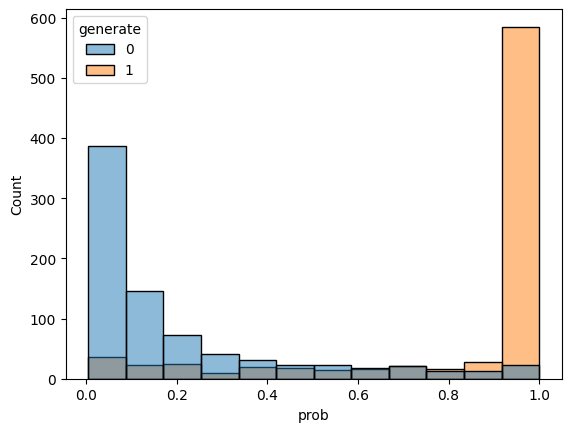

In [16]:
import seaborn as sns
sns.histplot(ret, x='prob', hue='generate')

In [6]:
import torch.nn as nn
from utils.models import *
from transformers import DataCollatorWithPadding

device = "cuda"
model = BertConv1dBinaryClassifier_MultiK(base).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=None)  # 균형이면 None
optimizer = get_optimizer(model)
collator = DataCollatorWithPadding(tokenizer=tok)

train_model(model, ds_mixed['train'], ds_mixed['validation'], optimizer, collator, criterion)


epoch 1 end
train_loss: 0.39995435609660923
val_loss: 0.3595839738845825
epoch 2 end
train_loss: 0.3285318033820783
val_loss: 0.35731783509254456
epoch 3 end
train_loss: 0.2797078004212361
val_loss: 0.3332432806491852
epoch 4 end
train_loss: 0.24576730390794754
val_loss: 0.367575079202652
epoch 5 end
train_loss: 0.19909231295477153
val_loss: 0.41291460394859314


<Axes: xlabel='prob', ylabel='Count'>

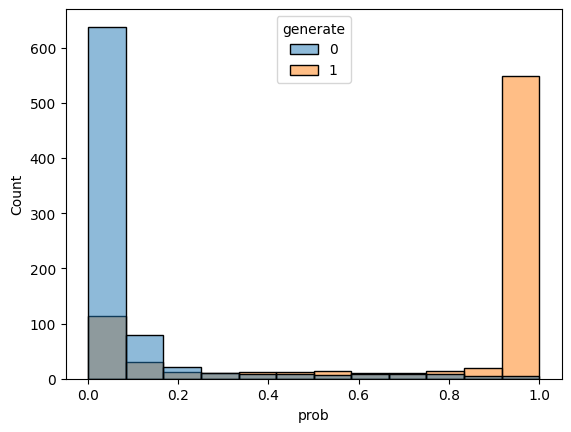

In [7]:
probs_generated, _ = get_preds(model, ds_generated['validation'], collator)
probs_non_generated, _ = get_preds(model, ds_non_generated['validation'].select(range(len(ds_generated['validation']))), collator)
import pandas as pd
ret = pd.DataFrame({
    'prob': probs_generated + probs_non_generated,
    'generate': [1]*len(probs_generated) + [0]*len(probs_non_generated),
})
import seaborn as sns
sns.histplot(ret, x='prob', hue='generate')

In [ ]:
import datasets 
get_accuracy(model, datasets.concatenate_datasets([ds_generated['validation'],ds_non_generated['validation'].select(range(len(ds_generated['validation'])))]),0.6,collator)

0.8514851485148515

<Axes: xlabel='prob', ylabel='Count'>

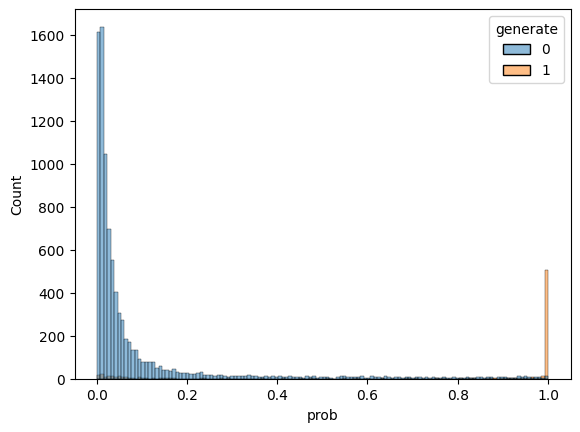

In [21]:
probs_generated, _ = get_preds(model, ds_generated['validation'], collator)
probs_non_generated, _ = get_preds(model, ds_non_generated['validation'], collator)
import pandas as pd
ret = pd.DataFrame({
    'prob': probs_generated + probs_non_generated,
    'generate': [1]*len(probs_generated) + [0]*len(probs_non_generated),
})
import seaborn as sns
sns.histplot(ret, x='prob', hue='generate')

<Axes: xlabel='prob', ylabel='Count'>

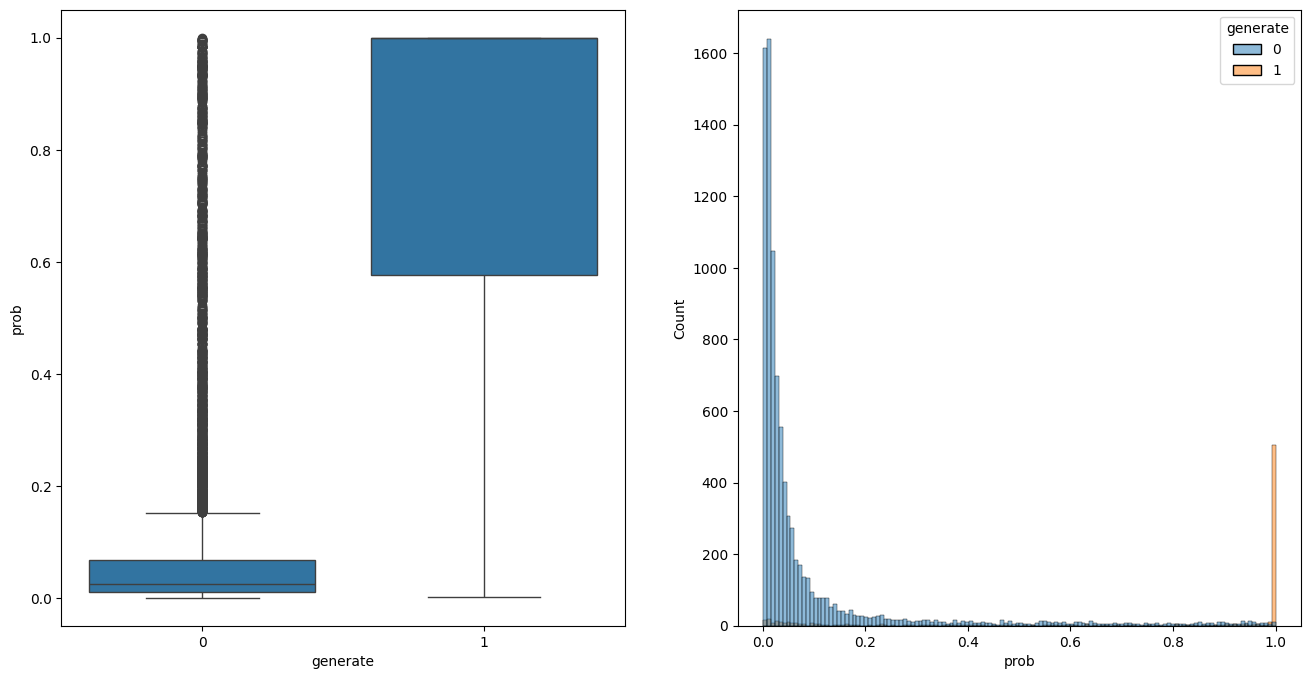

In [26]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(16,8))
sns.boxplot(ret, y='prob', x='generate',ax=ax[0])
sns.histplot(ret, x='prob', hue='generate')

In [27]:
save_model('multik_11_11.pth', model, optimizer, 16, 5)

In [22]:
get_accuracy(model, datasets.concatenate_datasets([ds_generated['validation'],ds_non_generated['validation']]),0.6,collator)

0.9420662687795843